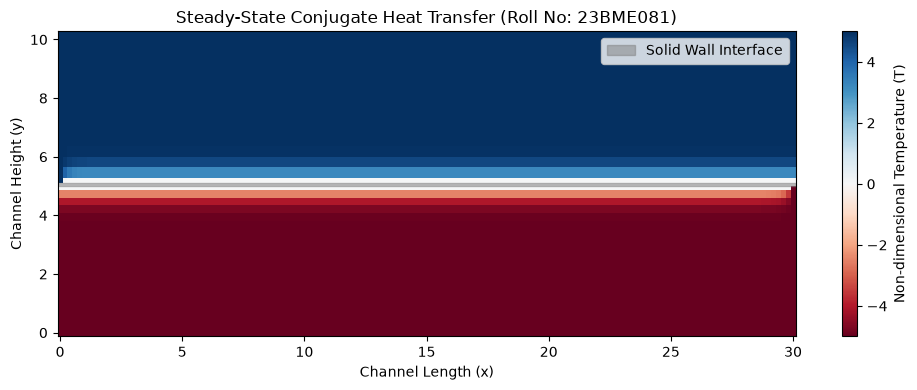

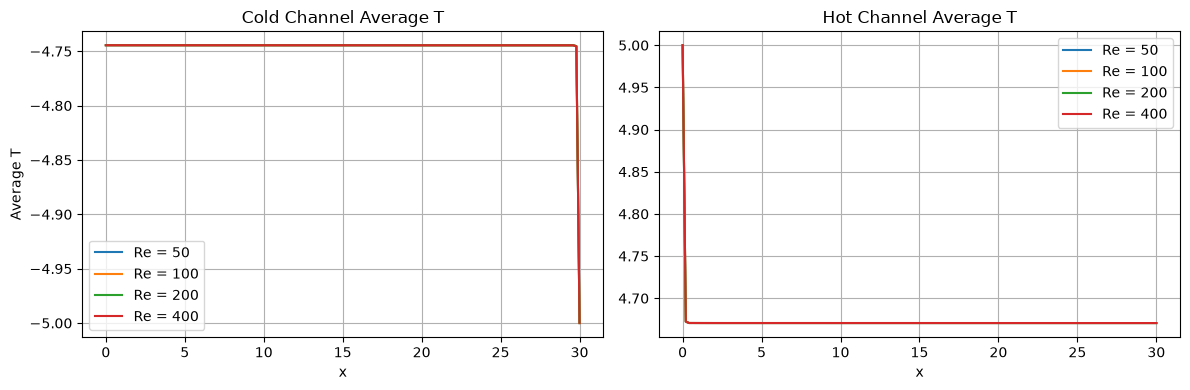

In [1]:
"""
  CFD & HT Lab - Experiment 2
  Topic: Double-Pipe Heat Exchanger - Conjugate Heat Transfer
  Student Name : Dev Pateliya
  Roll Number  : 23BME081
  Semester     : 7th Semester (B.Tech Mechanical Engineering)
"""

import numpy as np
import matplotlib.pyplot as plt

Lx = 30.0
th = 0.1
Dy_hot = 5.0
Dy_cold = 5.0
Ly = Dy_hot + Dy_cold + th

nx = 150
ny_hot = 15
ny_wall = 3
ny_cold = 20
ny = ny_hot + ny_wall + ny_cold

x_arr = np.linspace(0, Lx, nx)
y_cold = np.linspace(0, Dy_cold, ny_cold)
y_wall = np.linspace(Dy_cold, Dy_cold + th, ny_wall)
y_hot = np.linspace(Dy_cold + th, Ly, ny_hot)
y_arr = np.concatenate([y_cold, y_wall, y_hot])
X, Y = np.meshgrid(x_arr, y_arr)

dx = Lx / (nx - 1)
dy_hot = Dy_hot / (ny_hot - 1)
dy_wall = th / (ny_wall - 1)
dy_cold = Dy_cold / (ny_cold - 1)

k_f = 0.6
k_s = 400.0
Pr = 7.0
Re_hot = 10.0
Re_cold = 10.0
T_hot_in = 5.0
T_cold_in = -5.0
dp_cold = 1.0
dp_hot = 1.0
mu_cold = 1.0
mu_hot = 1.0
counter_flow = True

max_iter = 500000
tol = 1e-5

u = np.zeros((ny, nx))
R_hot = Dy_hot / 2.0
R_cold = Dy_cold / 2.0
yc = np.linspace(-R_cold, R_cold, ny_cold)
yh = np.linspace(-R_hot, R_hot, ny_hot)

prof_cold = (dp_cold / (2.0 * mu_cold * Lx)) * (R_cold**2 - yc**2)
prof_hot = (dp_hot / (2.0 * mu_hot * Lx)) * (R_hot**2 - yh**2)
sign_cold = -1.0 if counter_flow else 1.0

u[:ny_cold] = sign_cold * prof_cold[:, None]
u[ny_cold + ny_wall:] = prof_hot[:, None]

T = np.zeros((ny, nx))
T[:ny_cold, :] = T_cold_in
T[ny_cold + ny_wall:, :] = T_hot_in

D_cold_val = 1.0 / (Re_cold * Pr)
D_hot_val = 1.0 / (Re_hot * Pr)
D_wall_val = (k_s / k_f) * ((D_hot_val + D_cold_val) / 2.0)

D = np.zeros((ny, nx))
D[:ny_cold, :] = D_cold_val
D[ny_cold:ny_cold + ny_wall, :] = D_wall_val
D[ny_cold + ny_wall:, :] = D_hot_val

dy_vec = np.zeros((ny - 2, 1))
dy_vec[:ny_cold - 1, 0] = dy_cold
dy_vec[ny_cold - 1:ny_cold + ny_wall - 1, 0] = dy_wall
dy_vec[ny_cold + ny_wall - 1:, 0] = dy_hot


def apply_bc(T_field):
    if counter_flow:
        T_field[:ny_cold, -1] = T_cold_in
        T_field[:ny_cold, 0] = T_field[:ny_cold, 1]
    else:
        T_field[:ny_cold, 0] = T_cold_in
        T_field[:ny_cold, -1] = T_field[:ny_cold, -2]
        
    T_field[ny_cold + ny_wall:, 0] = T_hot_in
    T_field[ny_cold + ny_wall:, -1] = T_field[ny_cold + ny_wall:, -2]
    T_field[ny_cold:ny_cold + ny_wall, 0] = T_field[ny_cold:ny_cold + ny_wall, 1]
    T_field[ny_cold:ny_cold + ny_wall, -1] = T_field[ny_cold:ny_cold + ny_wall, -2]
    T_field[0, :] = T_field[1, :]
    T_field[-1, :] = T_field[-2, :]


apply_bc(T)

for it in range(max_iter):
    T_old = T.copy()
    
    Tc = T[1:-1, 1:-1]
    Te = T[1:-1, 2:]
    Tw = T[1:-1, :-2]
    Tn = T[2:, 1:-1]
    Ts = T[:-2, 1:-1]
    
    D_e = D[1:-1, 2:]
    D_w = D[1:-1, :-2]
    D_n = D[2:, 1:-1]
    D_s = D[:-2, 1:-1]
    
    diff_x = (D_e * (Te - Tc) - D_w * (Tc - Tw)) / (dx**2)
    diff_y = (D_n * (Tn - Tc) - D_s * (Tc - Ts)) / (dy_vec**2)
    
    uc = u[1:-1, 1:-1]
    dTdx_upwind = np.where(uc >= 0, (Tc - Tw) / dx, (Te - Tc) / dx)
    conv = uc * dTdx_upwind
    
    max_D = np.max(D)
    max_u = np.max(np.abs(uc))
    min_dy = min(dy_cold, dy_wall, dy_hot)
    dt = 0.4 / (max_D * (2 / dx**2 + 2 / min_dy**2) + max_u / dx)
    
    T[1:-1, 1:-1] = Tc + dt * (diff_x + diff_y - conv)
    apply_bc(T)
    
    err = np.max(np.abs(T - T_old))
    if err < tol:
        break

plt.figure(figsize=(10, 4))
mesh = plt.pcolormesh(X, Y, T, cmap='RdBu', shading='auto')
plt.colorbar(mesh, label='Non-dimensional Temperature (T)')
plt.axhspan(Dy_cold, Dy_cold + th, color='gray', alpha=0.5, label='Solid Wall Interface')
plt.title('Steady-State Conjugate Heat Transfer')
plt.xlabel('Channel Length (x)')
plt.ylabel('Channel Height (y)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# --- Parametric Study: Effect of Reynolds Number ---
re_values = [50, 100, 200, 400]
plt.figure(figsize=(12, 4))

for re in re_values:
    D_c_val = 1.0 / (re * Pr)
    D_h_val = 1.0 / (re * Pr)
    D_w_val = (k_s / k_f) * ((D_h_val + D_c_val) / 2.0)
    
    D_p = np.zeros((ny, nx))
    D_p[:ny_cold, :] = D_c_val
    D_p[ny_cold:ny_cold + ny_wall, :] = D_w_val
    D_p[ny_cold + ny_wall:, :] = D_h_val
    
    T_p = np.zeros((ny, nx))
    T_p[:ny_cold, :] = T_cold_in
    T_p[ny_cold + ny_wall:, :] = T_hot_in
    apply_bc(T_p)
    
    for _ in range(30000):
        T_old_p = T_p.copy()
        Tc = T_p[1:-1, 1:-1]
        
        diff_x = (D_p[1:-1, 2:] * (T_p[1:-1, 2:] - Tc) - D_p[1:-1, :-2] * (Tc - T_p[1:-1, :-2])) / (dx**2)
        diff_y = (D_p[2:, 1:-1] * (T_p[2:, 1:-1] - Tc) - D_p[:-2, 1:-1] * (Tc - T_p[:-2, 1:-1])) / (dy_vec**2)
        
        uc = u[1:-1, 1:-1]
        dTdx = np.where(uc >= 0, (Tc - T_p[1:-1, :-2]) / dx, (T_p[1:-1, 2:] - Tc) / dx)
        
        dt_p = 0.4 / (np.max(D_p) * (2 / dx**2 + 2 / min_dy**2) + np.max(np.abs(uc)) / dx)
        T_p[1:-1, 1:-1] = Tc + dt_p * (diff_x + diff_y - uc * dTdx)
        apply_bc(T_p)
        
        if np.max(np.abs(T_p - T_old_p)) < 1e-4:
            break
            
    T_avg_cold = T_p[:ny_cold, :].mean(axis=0)
    T_avg_hot = T_p[ny_cold + ny_wall:, :].mean(axis=0)
    
    plt.subplot(1, 2, 1)
    plt.plot(x_arr, T_avg_cold, label=f'Re = {re}')
    plt.subplot(1, 2, 2)
    plt.plot(x_arr, T_avg_hot, label=f'Re = {re}')

plt.subplot(1, 2, 1)
plt.title('Cold Channel Average T')
plt.xlabel('x')
plt.ylabel('Average T')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.title('Hot Channel Average T')
plt.xlabel('x')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()